# 04 — Baseline Global Model

**Goal** – Train and evaluate a global baseline model predicting
per-creator-relative video engagement at day 14.

Steps:
1. Load train/test splits and the pre-built feature matrix.
2. Compute trivial baselines (predict 0, predict creator mean).
3. Hyperparameter search: RandomForest and XGBoost (with / without follower count).
4. Final evaluation on the held-out test set.
5. Summary: metrics table, predicted vs actual, error distribution, per-creator RMSE.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


## 0. Load Data and Build Splits

In [3]:
import pandas as pd
import numpy as np

from creator_analytics.config import load_config
from creator_analytics.data import filter_creators, load_raw_table, train_test_split_by_creator
from creator_analytics.features import build_features
from creator_analytics.models import prepare_X
from creator_analytics.targets import build_target, get_nonmonotonic_video_ids
from creator_analytics.utils import set_seed

config = load_config("config/default.yaml")
set_seed(config["seed"])

RAW = config["paths"]["raw_dir"]
min_vids = config["data"]["min_videos_per_creator"]
SEED = config["seed"]

videos = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement = load_raw_table(RAW, "engagement_daily")

bad_ids = get_nonmonotonic_video_ids(engagement)
videos_clean = videos[~videos["video_id"].isin(bad_ids)].reset_index(drop=True)
videos_f = filter_creators(videos_clean, "author_id", min_videos=min_vids)

train_df, test_df = train_test_split_by_creator(
    videos_f, "author_id", test_size=config["split"]["test_size"], seed=SEED
)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])

from pathlib import Path
feat_path = Path("data/processed/features.parquet")
if feat_path.exists():
    features = pd.read_parquet(feat_path)
else:
    features = build_features(videos_f, creator_daily, train_video_ids=train_ids)
    feat_path.parent.mkdir(parents=True, exist_ok=True)
    features.to_parquet(str(feat_path), index=False)

rel_t = build_target(engagement, videos_f, day=14, mode="relative", train_video_ids=train_ids)
data = (features
        .merge(videos_f[["video_id", "author_id"]], on="video_id")
        .merge(rel_t, on="video_id"))

train_mask = data["video_id"].isin(train_ids)
test_mask  = data["video_id"].isin(test_ids)

X_all = prepare_X(data.drop(columns=["author_id", "target"]))
X_train = X_all[train_mask].reset_index(drop=True)
y_train = data.loc[train_mask, "target"].reset_index(drop=True)
author_train = data.loc[train_mask, "author_id"].reset_index(drop=True)

X_test = X_all[test_mask].reset_index(drop=True)
y_test = data.loc[test_mask, "target"].reset_index(drop=True)
author_test = data.loc[test_mask, "author_id"].reset_index(drop=True)

print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | Features: {X_train.shape[1]}")


Train: 160,492 rows | Test: 40,124 rows | Features: 53


## 1. Trivial Baselines

Two baselines that require no ML:

| Model | Prediction |
|-------|-----------|
| **predict_0** | Always 0 (= per-creator train median on relative target) |
| **predict_creator_mean** | Per-creator train mean |


In [4]:
from creator_analytics.models import trivial_zero_rmse, trivial_creator_mean

rmse_zero = trivial_zero_rmse(y_test)
rmse_cmean, preds_cmean = trivial_creator_mean(y_train, author_train, y_test, author_test)
print(f"predict_0 RMSE:            {rmse_zero:.4f}")
print(f"predict_creator_mean RMSE: {rmse_cmean:.4f}")


predict_0 RMSE:            1.0005
predict_creator_mean RMSE: 0.9690


## 2. RandomForest — Hyperparameter Search

StratifiedKFold (k=5) by author_id, 30 random iterations, RMSE.


In [5]:
from creator_analytics.models import search_random_forest

n_splits = config["cv"]["n_splits"]
rf_model = search_random_forest(X_train, y_train, author_train,
                                 n_splits=n_splits, seed=SEED, n_iter=30)
print(f"RF best CV RMSE: {rf_model.cv_rmse:.4f}")
print(f"Best params: {rf_model.params}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits


RF best CV RMSE: 0.9307
Best params: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None}


## 3. XGBoost — Hyperparameter Search (with and without follower count)

Manual random search with per-fold early stopping (early_stopping_rounds=50) on
the CV validation fold — **test set is never seen during search**.


In [6]:
from creator_analytics.models import search_xgboost

xgb_with = search_xgboost(X_train, y_train, author_train,
                            n_splits=n_splits, seed=SEED, n_iter=30)
xgb_nof  = search_xgboost(X_train, y_train, author_train,
                            n_splits=n_splits, seed=SEED, n_iter=30,
                            exclude_cols=["follower_count_log"])

print(f"XGB (with follower) CV RMSE: {xgb_with.cv_rmse:.4f}")
print(f"XGB (no  follower ) CV RMSE: {xgb_nof.cv_rmse:.4f}")
follower_delta = xgb_with.cv_rmse - xgb_nof.cv_rmse
print(f"Follower impact on CV RMSE: {follower_delta:+.4f}")

best_xgb = xgb_with if xgb_with.cv_rmse <= xgb_nof.cv_rmse else xgb_nof


XGB (with follower) CV RMSE: 0.9323
XGB (no  follower ) CV RMSE: 0.9461
Follower impact on CV RMSE: -0.0138


## 4. CV Summary — All Models


In [7]:
import pandas as pd

cv_summary = pd.DataFrame([
    {"model": "predict_0",               "cv_rmse": None,            "test_rmse": rmse_zero},
    {"model": "predict_creator_mean",    "cv_rmse": None,            "test_rmse": rmse_cmean},
    {"model": "RandomForest",            "cv_rmse": rf_model.cv_rmse, "test_rmse": None},
    {"model": "XGB_with_follower",       "cv_rmse": xgb_with.cv_rmse,"test_rmse": None},
    {"model": "XGB_no_follower",         "cv_rmse": xgb_nof.cv_rmse, "test_rmse": None},
]).set_index("model")
display(cv_summary.style.format({"cv_rmse": "{:.4f}", "test_rmse": "{:.4f}"}, na_rep="—"))


,cv_rmse,test_rmse
model,,
predict_0,—,1.0005
predict_creator_mean,—,0.9690
RandomForest,0.9307,—
XGB_with_follower,0.9323,—
XGB_no_follower,0.9461,—


## 5. Final Test Evaluation

The test set is touched **exactly once** — here.


In [8]:
from creator_analytics.evaluate import compute_metrics, compute_per_creator_metrics

# Trivial baselines
m_zero  = compute_metrics(y_test, np.zeros(len(y_test)))
m_cmean = compute_metrics(y_test, preds_cmean)

# RF
y_pred_rf = rf_model.predict(X_test)
m_rf = compute_metrics(y_test, y_pred_rf)

# XGB with follower
y_pred_xgb_with = xgb_with.predict(X_test)
m_xgb_with = compute_metrics(y_test, y_pred_xgb_with)

# XGB without follower
y_pred_xgb_nof = xgb_nof.predict(X_test)
m_xgb_nof = compute_metrics(y_test, y_pred_xgb_nof)

# Best model
y_pred_best = best_xgb.predict(X_test)
m_best = compute_metrics(y_test, y_pred_best)

results_df = pd.DataFrame({
    "predict_0":            m_zero,
    "predict_creator_mean": m_cmean,
    "RandomForest":         m_rf,
    "XGB_with_follower":    m_xgb_with,
    "XGB_no_follower":      m_xgb_nof,
}).T[["rmse","mae","r2","spearman","n"]]

display(results_df.style.format({"rmse":"{:.4f}","mae":"{:.4f}","r2":"{:.4f}","spearman":"{:.4f}"}))


,rmse,mae,r2,spearman,n
predict_0,1.0005,0.6030,-0.0215,nan,40124.000000
predict_creator_mean,0.9690,0.6339,0.0418,0.0759,40124.000000
RandomForest,0.9311,0.5947,0.1152,0.2759,40124.000000
XGB_with_follower,0.9321,0.5982,0.1133,0.2615,40124.000000
XGB_no_follower,0.9468,0.6043,0.0852,0.2381,40124.000000


## 6. Diagnostics


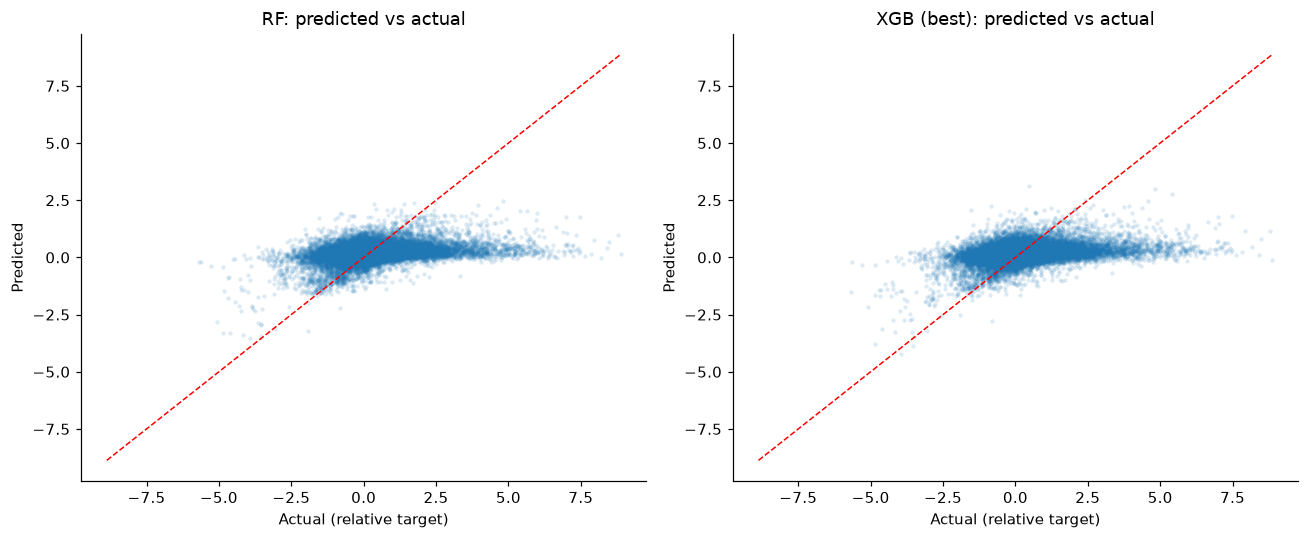

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, [
    ("RF", y_pred_rf),
    ("XGB (best)", y_pred_best),
]):
    ax.scatter(y_test, y_pred, alpha=0.15, s=8, linewidths=0)
    lim = max(abs(y_test.min()), abs(y_test.max()))
    ax.plot([-lim, lim], [-lim, lim], "r--", linewidth=1)
    ax.set_xlabel("Actual (relative target)")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}: predicted vs actual")

plt.tight_layout()
plt.show()


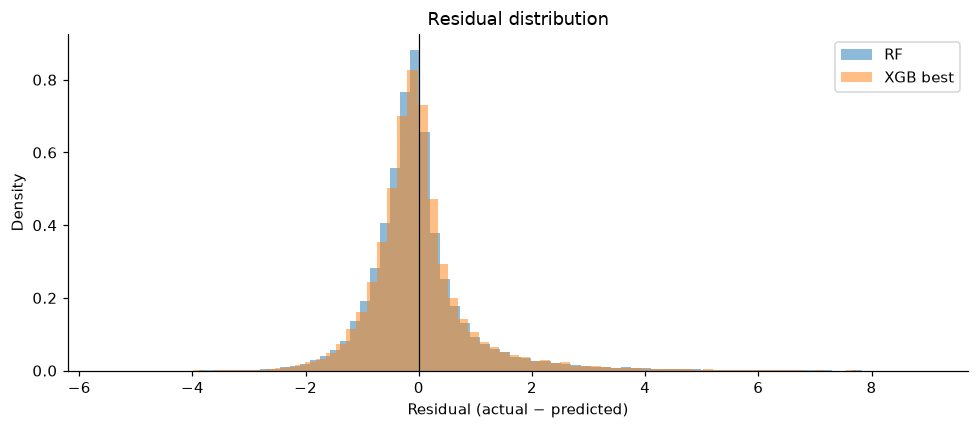

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
errors_rf   = y_test.values - y_pred_rf
errors_best = y_test.values - y_pred_best
ax.hist(errors_rf,   bins=80, alpha=0.5, label="RF",       density=True)
ax.hist(errors_best, bins=80, alpha=0.5, label="XGB best", density=True)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Residual (actual − predicted)")
ax.set_ylabel("Density")
ax.set_title("Residual distribution")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Per-Creator Analysis


In [11]:
per_creator = compute_per_creator_metrics(y_test, pd.Series(y_pred_best), author_test)
print(f"Creators in test: {len(per_creator)}")
print(f"\nTop 5 worst (highest RMSE):")
display(per_creator.nlargest(5, "rmse"))
print(f"\nTop 5 best (lowest RMSE):")
display(per_creator.nsmallest(5, "rmse"))


Creators in test: 1437

Top 5 worst (highest RMSE):


,author_id,n_test,rmse,mae,spearman
1353,7173797994882581550,7,2.965003,2.559364,0.000000
998,6880719370957603846,17,2.570190,1.307999,-0.262255
67,1818728,10,2.438502,1.567515,0.757576
779,6823500943611528198,17,2.423963,1.945629,0.379902
313,6760420560305816582,8,2.359268,1.576108,0.047619



Top 5 best (lowest RMSE):


,author_id,n_test,rmse,mae,spearman
750,6821402140621554693,6,0.093437,0.073791,0.657143
24,1365467,22,0.126666,0.094184,0.787348
1388,7810949,6,0.148618,0.117463,0.600000
449,6790109969108419589,6,0.154734,0.139873,0.771429
1032,6901839038505812997,14,0.155467,0.123166,0.059341


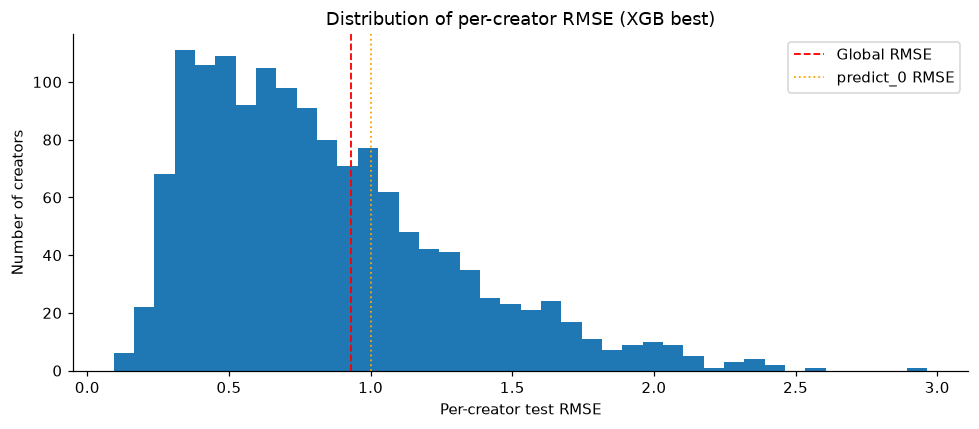

432 / 1437 creators where model is worse than predict_0


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(per_creator["rmse"], bins=40, edgecolor="none")
ax.axvline(m_best["rmse"], color="red", linestyle="--", linewidth=1.2, label="Global RMSE")
ax.axvline(rmse_zero, color="orange", linestyle=":", linewidth=1.2, label="predict_0 RMSE")
ax.set_xlabel("Per-creator test RMSE")
ax.set_ylabel("Number of creators")
ax.set_title("Distribution of per-creator RMSE (XGB best)")
ax.legend()
plt.tight_layout()
plt.show()

n_worse = (per_creator["rmse"] > rmse_zero).sum()
print(f"{n_worse} / {len(per_creator)} creators where model is worse than predict_0")


## 8. Save Artefacts


In [13]:
from pathlib import Path
from creator_analytics.evaluate import log_experiment, save_metrics
import datetime

today = datetime.date.today().isoformat()
exp_path = config["paths"].get("experiments_log", "results/experiments.md")
metrics_path = config["paths"].get("metrics", "results/metrics.json")

for name, m_base in [("predict_0", m_zero), ("predict_creator_mean", m_cmean)]:
    log_experiment(exp_path, name, today, "none", name, {}, None,
                   {"rmse": m_base["rmse"], "r2": m_base["r2"],
                    "spearman": m_base["spearman"]})

log_experiment(exp_path, "RF_global", today, "all_54", "RandomForest",
               rf_model.params, rf_model.cv_rmse, m_rf)
log_experiment(exp_path, "XGB_with_follower", today, "all_54", "XGBoost",
               xgb_with.params, xgb_with.cv_rmse, m_xgb_with)
log_experiment(exp_path, "XGB_no_follower", today, "all_54_no_follower", "XGBoost",
               xgb_nof.params, xgb_nof.cv_rmse, m_xgb_nof)

save_metrics({
    "trivial_predict_0_rmse":       m_zero["rmse"],
    "trivial_creator_mean_rmse":    m_cmean["rmse"],
    "rf_cv_rmse":                   rf_model.cv_rmse,
    "rf_test_rmse":                 m_rf["rmse"],
    "xgb_with_follower_cv_rmse":    xgb_with.cv_rmse,
    "xgb_with_follower_test_rmse":  m_xgb_with["rmse"],
    "xgb_no_follower_cv_rmse":      xgb_nof.cv_rmse,
    "xgb_no_follower_test_rmse":    m_xgb_nof["rmse"],
}, metrics_path)

# Save best model
best_xgb.model_name = "global_xgb_best"
best_xgb.save("models/global_xgb.joblib")

# Save predictions
pred_path = Path("results/predictions_global.parquet")
pred_path.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "y_true": y_test.values, "y_pred": y_pred_best, "author_id": author_test.values
}).to_parquet(str(pred_path), index=False)

per_creator.to_parquet("results/per_creator_metrics_global.parquet", index=False)

print("Saved: models/global_xgb.joblib")
print("Saved: results/metrics.json")
print("Saved: results/predictions_global.parquet")
print("Saved: results/per_creator_metrics_global.parquet")
print("Saved: results/experiments.md")


Saved: models/global_xgb.joblib
Saved: results/metrics.json
Saved: results/predictions_global.parquet
Saved: results/per_creator_metrics_global.parquet
Saved: results/experiments.md


## Summary

| Model | CV RMSE | Test RMSE | Test MAE | Test R² | Test Spearman |
|-------|---------|-----------|----------|---------|---------------|


In [14]:
summary_rows = [
    ("predict_0",            None,             m_zero["rmse"],    m_zero["mae"],    m_zero["r2"],    float("nan")),
    ("predict_creator_mean", None,             m_cmean["rmse"],   m_cmean["mae"],   m_cmean["r2"],   float("nan")),
    ("RandomForest",         rf_model.cv_rmse, m_rf["rmse"],      m_rf["mae"],      m_rf["r2"],      m_rf["spearman"]),
    ("XGB_with_follower",    xgb_with.cv_rmse, m_xgb_with["rmse"],m_xgb_with["mae"],m_xgb_with["r2"],m_xgb_with["spearman"]),
    ("XGB_no_follower",      xgb_nof.cv_rmse,  m_xgb_nof["rmse"], m_xgb_nof["mae"], m_xgb_nof["r2"], m_xgb_nof["spearman"]),
]
summary_df = pd.DataFrame(summary_rows,
    columns=["model", "cv_rmse", "test_rmse", "test_mae", "test_r2", "test_spearman"]
).set_index("model")
display(summary_df.style.format({
    "cv_rmse":      "{:.4f}", "test_rmse": "{:.4f}", "test_mae": "{:.4f}",
    "test_r2":      "{:.4f}", "test_spearman": "{:.4f}",
}, na_rep="—"))

follower_impact = m_xgb_with["rmse"] - m_xgb_nof["rmse"]
print(f"\nFollower count impact on test RMSE: {follower_impact:+.4f}")
print(f"(negative = model WITH follower is better)")

n_worse = (per_creator["rmse"] > rmse_zero).sum()
print(f"\nCreators where model > predict_0 RMSE: {n_worse} / {len(per_creator)}")
print(f"Best hyperparams (XGB best):")
for k, v in best_xgb.params.items():
    print(f"  {k}: {v}")


,cv_rmse,test_rmse,test_mae,test_r2,test_spearman
model,,,,,
predict_0,—,1.0005,0.6030,-0.0215,—
predict_creator_mean,—,0.9690,0.6339,0.0418,—
RandomForest,0.9307,0.9311,0.5947,0.1152,0.2759
XGB_with_follower,0.9323,0.9321,0.5982,0.1133,0.2615
XGB_no_follower,0.9461,0.9468,0.6043,0.0852,0.2381



Follower count impact on test RMSE: -0.0147
(negative = model WITH follower is better)

Creators where model > predict_0 RMSE: 432 / 1437
Best hyperparams (XGB best):
  max_depth: 6
  learning_rate: 0.05
  subsample: 0.85
  colsample_bytree: 0.84
  reg_alpha: 0.0
  reg_lambda: 1.23
  min_child_weight: 10
  n_estimators: 1215
